# Time Series Analysis - Homework 5

- Author: Elias Schweighuber
- Course: TIS

Goal: Forecast 70 monthly store-department revenue series (2012-01 to 2015-12) using global machine learning and deep learning models. Use 2014 (24 months train) as Validation to choose settings and 2015 (36 months train) as Test to report results. Compare against Seasonal Naive (Assignment 3) and AutoARIMA (best statistical model from Assignment 4).

In [1]:
import logging
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from neuralforecast import NeuralForecast
from neuralforecast.models import KAN, MLP, NHITS
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA

warnings.filterwarnings("ignore")
for name in ["pytorch_lightning", "lightning_fabric", "lightning.pytorch", "neuralforecast"]:
    logging.getLogger(name).setLevel(logging.ERROR)

## Step 1 - Aggregate One Level Lower

Aggregate the raw transactions to monthly revenue per store and department (10 stores x 7 departments = 70 series, 2012-01 to 2015-12). Verify that there are 48 months with no gaps and that the 70 series sum to the exact same monthly revenue as the 7 departments from Assignment 3.

In [2]:
data_dir = Path("../hw1/data")
sales_lazy = pl.scan_parquet(data_dir / "sales_combined.parquet")

all_cols = sales_lazy.collect_schema().names()
index_cols = ["item_id", "dept_id", "cat_id", "store_id", "state_id"]
date_cols = [c for c in all_cols if c not in index_cols and "2012-01-01" <= c <= "2015-12-31"]

long_sales = sales_lazy.select(index_cols + date_cols).unpivot(
    index=index_cols,
    on=date_cols,
    variable_name="date",
    value_name="sales",
)

calendar = pl.scan_csv(data_dir / "calendar.csv").select(["date", "wm_yr_wk"])
sell_prices = pl.scan_csv(data_dir / "sell_prices.csv")

rev_lazy = (
    long_sales
    .join(calendar, on="date", how="left")
    .join(sell_prices, on=["store_id", "item_id", "wm_yr_wk"], how="left")
    .with_columns(
        (pl.col("sales").fill_null(0).cast(pl.Float64) * pl.col("sell_price").fill_null(0.0)).alias("revenue"),
        pl.col("date").str.slice(0, 7).alias("month"),
    )
)

store_dept_df = (
    rev_lazy
    .group_by(["store_id", "dept_id", "month"])
    .agg(pl.col("revenue").sum())
    .sort(["store_id", "dept_id", "month"])
    .collect()
    .to_pandas()
)

dept_direct_df = (
    rev_lazy
    .group_by(["dept_id", "month"])
    .agg(pl.col("revenue").sum())
    .sort(["dept_id", "month"])
    .collect()
    .to_pandas()
    .pivot(index="month", columns="dept_id", values="revenue")
)

store_dept_df["unique_id"] = store_dept_df["store_id"] + "__" + store_dept_df["dept_id"]
df_bottom = store_dept_df.pivot(index="month", columns="unique_id", values="revenue").sort_index()
series_ids = list(df_bottom.columns)
depts = sorted(store_dept_df["dept_id"].unique().tolist())

# Aggregate bottom series up to departments and TOTAL
def aggregate_to_top(bottom_df):
    out = pd.DataFrame(index=bottom_df.index)
    for d in depts:
        cols = [c for c in bottom_df.columns if c.endswith("__" + d)]
        out[d] = bottom_df[cols].sum(axis=1)
    out["TOTAL"] = bottom_df.sum(axis=1)
    return out

df_top = aggregate_to_top(df_bottom)

# Integrity checks
expected_months = pd.date_range("2012-01-01", "2015-12-01", freq="MS").strftime("%Y-%m").tolist()
assert df_bottom.shape == (48, 70), f"Expected (48, 70), got {df_bottom.shape}"
assert list(df_bottom.index) == expected_months, "Month index has gaps"
assert int(df_bottom.isna().sum().sum()) == 0, "Missing values found"

max_diff = float(np.abs(df_top[depts] - dept_direct_df[depts]).max().max())
assert max_diff < 1e-6, f"Mismatch between store-dept sum and dept revenue: {max_diff}"

print(f"Bottom shape: {df_bottom.shape} (48 months x 70 series, no gaps)")
print(f"Max diff vs 7-department revenue: ${max_diff:.8f} (matches to the cent)")
print(f"Min store-dept monthly revenue: ${df_bottom.min().min():,.2f}")

Bottom shape: (48, 70) (48 months x 70 series, no gaps)
Max diff vs 7-department revenue: $0.00000003 (matches to the cent)
Min store-dept monthly revenue: $453.07


## Step 2 and Step 3 - Global Models and Two-Level Evaluation

Every ML and DL model is fitted once globally on all 70 store-department series.
Each forecast has 70 series x 12 months = 840 values and is scored twice:
- Bottom level (`Department + Store`, index `all 70`): metrics computed over all 840 values at once.
- Top level (`Department` and `Total`): sum the 10 stores per department and all 70 series for `TOTAL`, then score each series.

In [3]:
def compute_metrics(y_true, y_pred, y_train):
    err = y_true - y_pred
    mae = float(np.mean(np.abs(err)))
    mape = float(np.mean(np.abs(err / y_true)) * 100.0)
    wmape = float(np.sum(np.abs(err)) / np.sum(y_true) * 100.0)
    ss_res = float(np.sum(err ** 2))
    ss_tot = float(np.sum((y_true - np.mean(y_true)) ** 2))
    r2 = 1.0 - ss_res / ss_tot if ss_tot != 0 else np.nan
    scale = float(np.mean(np.abs(y_train[..., 12:] - y_train[..., :-12])))
    mase = mae / scale if scale != 0 else np.nan
    return {"MAE": mae, "MAPE": mape, "wMAPE": wmape, "MASE": mase, "R2": r2}

def seasonal_naive_forecast(y, h=12):
    # Same code as Assignment 3
    return y[-12:].copy().astype(float)

def run_seasonal_naive(train_df, h=12):
    preds = np.column_stack([seasonal_naive_forecast(train_df[c].values, h=h) for c in series_ids])
    return pd.DataFrame(preds, columns=series_ids)

def run_autoarima_a4(top_df, split, h=12):
    # Best statistical model from Assignment 4 (lowest Mean MASE across 7 departments)
    dates = pd.date_range("2012-01-01", periods=split, freq="MS")
    top_cols = depts + ["TOTAL"]
    sf_df = pd.DataFrame({
        "unique_id": np.repeat(top_cols, split),
        "ds": np.tile(dates, len(top_cols)),
        "y": top_df[top_cols].iloc[:split].values.T.reshape(-1),
    })
    sf = StatsForecast(models=[AutoARIMA(season_length=12)], freq="MS", n_jobs=1)
    sf.fit(sf_df)
    fc = sf.predict(h=h)
    return fc.pivot(index="ds", columns="unique_id", values="AutoARIMA")[top_cols].reset_index(drop=True)

## Step 4 and Step 5 - Features and Models

We compare two feature sets for the global machine learning models (recursive 1-step-ahead forecasting so no future data leaks):
- `Lag`: lag 1, lag 2, lag 3, lag 12
- `Lag + statistical`: lag 1, lag 2, lag 3, lag 12, 3-month rolling mean, 3-month rolling std, 12-month rolling mean, month sin and cos

Models:
- Benchmarks: `Seasonal Naive` (from Assignment 3) and `AutoARIMA (A4)` (best statistical model from Assignment 4, top level only).
- Machine Learning (3 global models): `HistGradientBoosting` (tree-based), `Ridge` (linear), `RandomForest` (own choice).
- Deep Learning (3 global models from `neuralforecast`, `h=12`, `input_size=12`, standard scaling): `MLP`, `NHITS`, `KAN`.

First, we run all models on the 2014 Validation window (24 months train) to choose the feature set for each ML model.

In [4]:
def build_step_features(hist, t, month_num, feature_set):
    lag1 = hist[t - 1]
    lag2 = hist[t - 2]
    lag3 = hist[t - 3]
    lag12 = hist[t - 12]
    if feature_set == "Lag":
        return np.column_stack([lag1, lag2, lag3, lag12])
    roll3 = hist[t - 3:t].mean(axis=0)
    roll3_std = hist[t - 3:t].std(axis=0)
    roll12 = hist[t - 12:t].mean(axis=0)
    msin = np.full(hist.shape[1], np.sin(2.0 * np.pi * month_num / 12.0))
    mcos = np.full(hist.shape[1], np.cos(2.0 * np.pi * month_num / 12.0))
    return np.column_stack([lag1, lag2, lag3, lag12, roll3, roll3_std, roll12, msin, mcos])

def run_global_ml(model, train_df, h=12, feature_set="Lag"):
    train_vals = train_df[series_ids].values.astype(float)
    T = train_vals.shape[0]
    X_rows, y_rows = [], []
    for t in range(12, T):
        m_num = (t % 12) + 1
        X_rows.append(build_step_features(train_vals, t, m_num, feature_set))
        y_rows.append(train_vals[t])
    model.fit(np.vstack(X_rows), np.concatenate(y_rows))

    hist = train_vals.copy()
    preds = []
    for step in range(h):
        t = T + step
        m_num = (t % 12) + 1
        y_hat = model.predict(build_step_features(hist, t, m_num, feature_set))
        preds.append(y_hat)
        hist = np.vstack([hist, y_hat])
    return pd.DataFrame(np.array(preds), columns=series_ids)

def run_global_dl(train_df, h=12):
    split = len(train_df)
    dates = pd.date_range("2012-01-01", periods=split, freq="MS")
    nf_df = pd.DataFrame({
        "unique_id": np.repeat(series_ids, split),
        "ds": np.tile(dates, len(series_ids)),
        "y": train_df[series_ids].values.T.reshape(-1),
    })
    common = dict(
        h=h,
        input_size=12,
        max_steps=300,
        scaler_type="standard",
        random_seed=42,
        enable_progress_bar=False,
        enable_model_summary=False,
        logger=False,
        accelerator="cpu",
    )
    nf = NeuralForecast(models=[MLP(**common), NHITS(**common), KAN(**common)], freq="MS")
    nf.fit(df=nf_df)
    fc = nf.predict()
    out = {}
    for mname in ["MLP", "NHITS", "KAN"]:
        out[mname] = fc.pivot(index="ds", columns="unique_id", values=mname)[series_ids].reset_index(drop=True)
    return out

def make_ml_model(name):
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    if name == "HistGradientBoosting":
        return HistGradientBoostingRegressor(max_depth=5, max_iter=150, random_state=42)
    if name == "RandomForest":
        return RandomForestRegressor(n_estimators=150, max_depth=10, random_state=42, n_jobs=-1)
    raise ValueError(name)

In [5]:
# Validation window: train 2012-01..2013-12 (24m), forecast 2014 (12m)
val_train_bot = df_bottom.iloc[:24]
val_true_bot = df_bottom.iloc[24:36]
val_train_top = df_top.iloc[:24]
val_true_top = df_top.iloc[24:36]

val_bot_preds = {}
val_top_preds = {}

# Benchmarks
val_bot_preds[("Seasonal Naive", "Lag 12")] = run_seasonal_naive(val_train_bot)
val_top_preds[("Seasonal Naive", "Lag 12")] = aggregate_to_top(val_bot_preds[("Seasonal Naive", "Lag 12")])
val_top_preds[("AutoARIMA (A4)", "Univariate")] = run_autoarima_a4(df_top, split=24)

# ML models on both feature sets
for mname in ["Ridge", "HistGradientBoosting", "RandomForest"]:
    for fs in ["Lag", "Lag + statistical"]:
        p = run_global_ml(make_ml_model(mname), val_train_bot, h=12, feature_set=fs)
        val_bot_preds[(mname, fs)] = p
        val_top_preds[(mname, fs)] = aggregate_to_top(p)

# DL models
dl_val = run_global_dl(val_train_bot, h=12)
for mname, p in dl_val.items():
    val_bot_preds[(mname, "Lag (12m)")] = p
    val_top_preds[(mname, "Lag (12m)")] = aggregate_to_top(p)

# Validation summary table
val_rows = []
for (mname, fs), p_top in val_top_preds.items():
    m_tot = compute_metrics(val_true_top["TOTAL"].values, p_top["TOTAL"].values, val_train_top["TOTAL"].values)
    if (mname, fs) in val_bot_preds:
        p_bot = val_bot_preds[(mname, fs)]
        m_bot = compute_metrics(val_true_bot.values.T, p_bot.values.T, val_train_bot.values.T)
        bot_mae, bot_mase, bot_r2 = m_bot["MAE"], m_bot["MASE"], m_bot["R2"]
    else:
        bot_mae, bot_mase, bot_r2 = np.nan, np.nan, np.nan
    val_rows.append({
        "Model": mname,
        "Feature set": fs,
        "Val Bottom MAE": bot_mae,
        "Val Bottom MASE": bot_mase,
        "Val Bottom R2": bot_r2,
        "Val TOTAL wMAPE (%)": m_tot["wMAPE"],
    })

val_summary = pd.DataFrame(val_rows).sort_values("Val Bottom MAE", na_position="last").reset_index(drop=True)
display(val_summary.style.format({
    "Val Bottom MAE": "${:,.2f}",
    "Val Bottom MASE": "{:.3f}",
    "Val Bottom R2": "{:.3f}",
    "Val TOTAL wMAPE (%)": "{:.2f}%",
}, na_rep="-"))

,Model,Feature set,Val Bottom MAE,Val Bottom MASE,Val Bottom R2,Val TOTAL wMAPE (%)
0,MLP,Lag (12m),"$4,369.37",0.615,0.975,1.52%
1,Ridge,Lag,"$4,512.59",0.635,0.969,2.78%
2,KAN,Lag (12m),"$4,566.10",0.643,0.972,1.84%
3,RandomForest,Lag,"$4,704.21",0.662,0.968,2.90%
4,NHITS,Lag (12m),"$4,927.77",0.694,0.967,2.17%
5,Ridge,Lag + statistical,"$4,957.47",0.698,0.967,4.13%
6,RandomForest,Lag + statistical,"$5,067.17",0.713,0.962,2.06%
7,Seasonal Naive,Lag 12,"$5,145.20",0.724,0.961,5.12%
8,HistGradientBoosting,Lag,"$5,274.92",0.743,0.951,3.62%
9,HistGradientBoosting,Lag + statistical,"$5,283.37",0.744,0.955,1.92%


### Validation Feature-Set Selection

From the 2014 Validation table above:
- `Ridge`: `Lag` beats `Lag + statistical` on both Bottom MAE and TOTAL wMAPE, so we pick `Lag`.
- `RandomForest`: `Lag` has clearly lower Bottom MAE than `Lag + statistical`, so we pick `Lag`.
- `HistGradientBoosting`: `Lag + statistical` has nearly identical Bottom MAE and much better TOTAL wMAPE (1.92% vs 3.62%), so we pick `Lag + statistical`.
- Among DL models, `MLP` wins Validation on both Bottom MAE and TOTAL wMAPE.

Now we fit the selected models on the 2015 Test window (36 months train, 2012-01 to 2014-12) and report test metrics.

In [6]:
# Test window: train 2012-01..2014-12 (36m), forecast 2015 (12m)
test_train_bot = df_bottom.iloc[:36]
test_true_bot = df_bottom.iloc[36:48]
test_train_top = df_top.iloc[:36]
test_true_top = df_top.iloc[36:48]

selected_ml = [
    ("Ridge", "Lag"),
    ("HistGradientBoosting", "Lag + statistical"),
    ("RandomForest", "Lag"),
]

test_bot_preds = {}
test_top_preds = {}

# Benchmarks
test_bot_preds[("Seasonal Naive", "Lag 12")] = run_seasonal_naive(test_train_bot)
test_top_preds[("Seasonal Naive", "Lag 12")] = aggregate_to_top(test_bot_preds[("Seasonal Naive", "Lag 12")])
test_top_preds[("AutoARIMA (A4)", "Univariate")] = run_autoarima_a4(df_top, split=36)

# Selected ML models
for mname, fs in selected_ml:
    p = run_global_ml(make_ml_model(mname), test_train_bot, h=12, feature_set=fs)
    test_bot_preds[(mname, fs)] = p
    test_top_preds[(mname, fs)] = aggregate_to_top(p)

# DL models
dl_test = run_global_dl(test_train_bot, h=12)
for mname, p in dl_test.items():
    test_bot_preds[(mname, "Lag (12m)")] = p
    test_top_preds[(mname, "Lag (12m)")] = aggregate_to_top(p)

print("Test forecasts ready for", len(test_top_preds), "models.")

Test forecasts ready for 8 models.


## Step 6 - One Table

One table for all levels, indices, feature sets, and models on the 2015 Test window.
The `Best` column marks the winner of each block:
- At the top levels (`Total` and `Department`), best is lowest `wMAPE`.
- At the bottom level (`Department + Store`, index `all 70`), best is lowest `MAE`.

In [7]:
model_order = [
    ("Seasonal Naive", "Lag 12"),
    ("AutoARIMA (A4)", "Univariate"),
    ("Ridge", "Lag"),
    ("HistGradientBoosting", "Lag + statistical"),
    ("RandomForest", "Lag"),
    ("MLP", "Lag (12m)"),
    ("NHITS", "Lag (12m)"),
    ("KAN", "Lag (12m)"),
]

rows = []

# 1. Total block
block = []
for mname, fs in model_order:
    m = compute_metrics(
        test_true_top["TOTAL"].values,
        test_top_preds[(mname, fs)]["TOTAL"].values,
        test_train_top["TOTAL"].values,
    )
    block.append({"Level": "Total", "Index": "TOTAL", "Feature set": fs, "Model": mname, **m})
best_m = min(block, key=lambda r: r["wMAPE"])["Model"]
for r in block:
    r["Best"] = "Best" if r["Model"] == best_m else ""
rows.extend(block)

# 2. Department blocks
for d in depts:
    block = []
    for mname, fs in model_order:
        m = compute_metrics(
            test_true_top[d].values,
            test_top_preds[(mname, fs)][d].values,
            test_train_top[d].values,
        )
        block.append({"Level": "Department", "Index": d, "Feature set": fs, "Model": mname, **m})
    best_m = min(block, key=lambda r: r["wMAPE"])["Model"]
    for r in block:
        r["Best"] = "Best" if r["Model"] == best_m else ""
    rows.extend(block)

# 3. Bottom level block (all 70 series together, 840 values)
block = []
for mname, fs in model_order:
    if (mname, fs) not in test_bot_preds:
        continue
    m = compute_metrics(
        test_true_bot.values.T,
        test_bot_preds[(mname, fs)].values.T,
        test_train_bot.values.T,
    )
    block.append({"Level": "Department + Store", "Index": "all 70", "Feature set": fs, "Model": mname, **m})
best_m = min(block, key=lambda r: r["MAE"])["Model"]
for r in block:
    r["Best"] = "Best" if r["Model"] == best_m else ""
rows.extend(block)

results_df = pd.DataFrame(rows)

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 140)

fmt_df = results_df.copy()
fmt_df["MAE"] = fmt_df["MAE"].map(lambda x: f"${x:,.2f}")
fmt_df["MAPE"] = fmt_df["MAPE"].map(lambda x: f"{x:.2f}%")
fmt_df["wMAPE"] = fmt_df["wMAPE"].map(lambda x: f"{x:.2f}%")
fmt_df["MASE"] = fmt_df["MASE"].map(lambda x: f"{x:.3f}")
fmt_df["R2"] = fmt_df["R2"].map(lambda x: f"{x:.3f}")
display(fmt_df)

,Level,Index,Feature set,Model,MAE,MAPE,wMAPE,MASE,R2,Best
0,Total,TOTAL,Lag 12,Seasonal Naive,"$379,545.28",10.69%,10.74%,1.747,-3.444,
1,Total,TOTAL,Univariate,AutoARIMA (A4),"$156,364.59",4.36%,4.42%,0.720,0.122,Best
2,Total,TOTAL,Lag,Ridge,"$218,521.10",6.04%,6.18%,1.006,-0.882,
3,Total,TOTAL,Lag + statistical,HistGradientBoosting,"$162,763.82",4.51%,4.60%,0.749,-0.026,
4,Total,TOTAL,Lag,RandomForest,"$241,487.30",6.68%,6.83%,1.112,-1.167,
5,Total,TOTAL,Lag (12m),MLP,"$205,988.84",5.73%,5.83%,0.948,-0.509,
6,Total,TOTAL,Lag (12m),NHITS,"$186,088.13",5.18%,5.26%,0.857,-0.226,
7,Total,TOTAL,Lag (12m),KAN,"$196,352.64",5.44%,5.55%,0.904,-0.390,
8,Department,FOODS_1,Lag 12,Seasonal Naive,"$28,135.21",11.43%,11.60%,2.456,-2.652,
9,Department,FOODS_1,Univariate,AutoARIMA (A4),"$15,091.77",6.20%,6.22%,1.317,-0.124,


## Step 7 - Figures

### Figure 1: Actual vs Forecasted Revenue (7 Departments and TOTAL)

Five models are shown across both Validation (2014, dashed) and Test (2015, solid) windows, with both forecast origins marked.

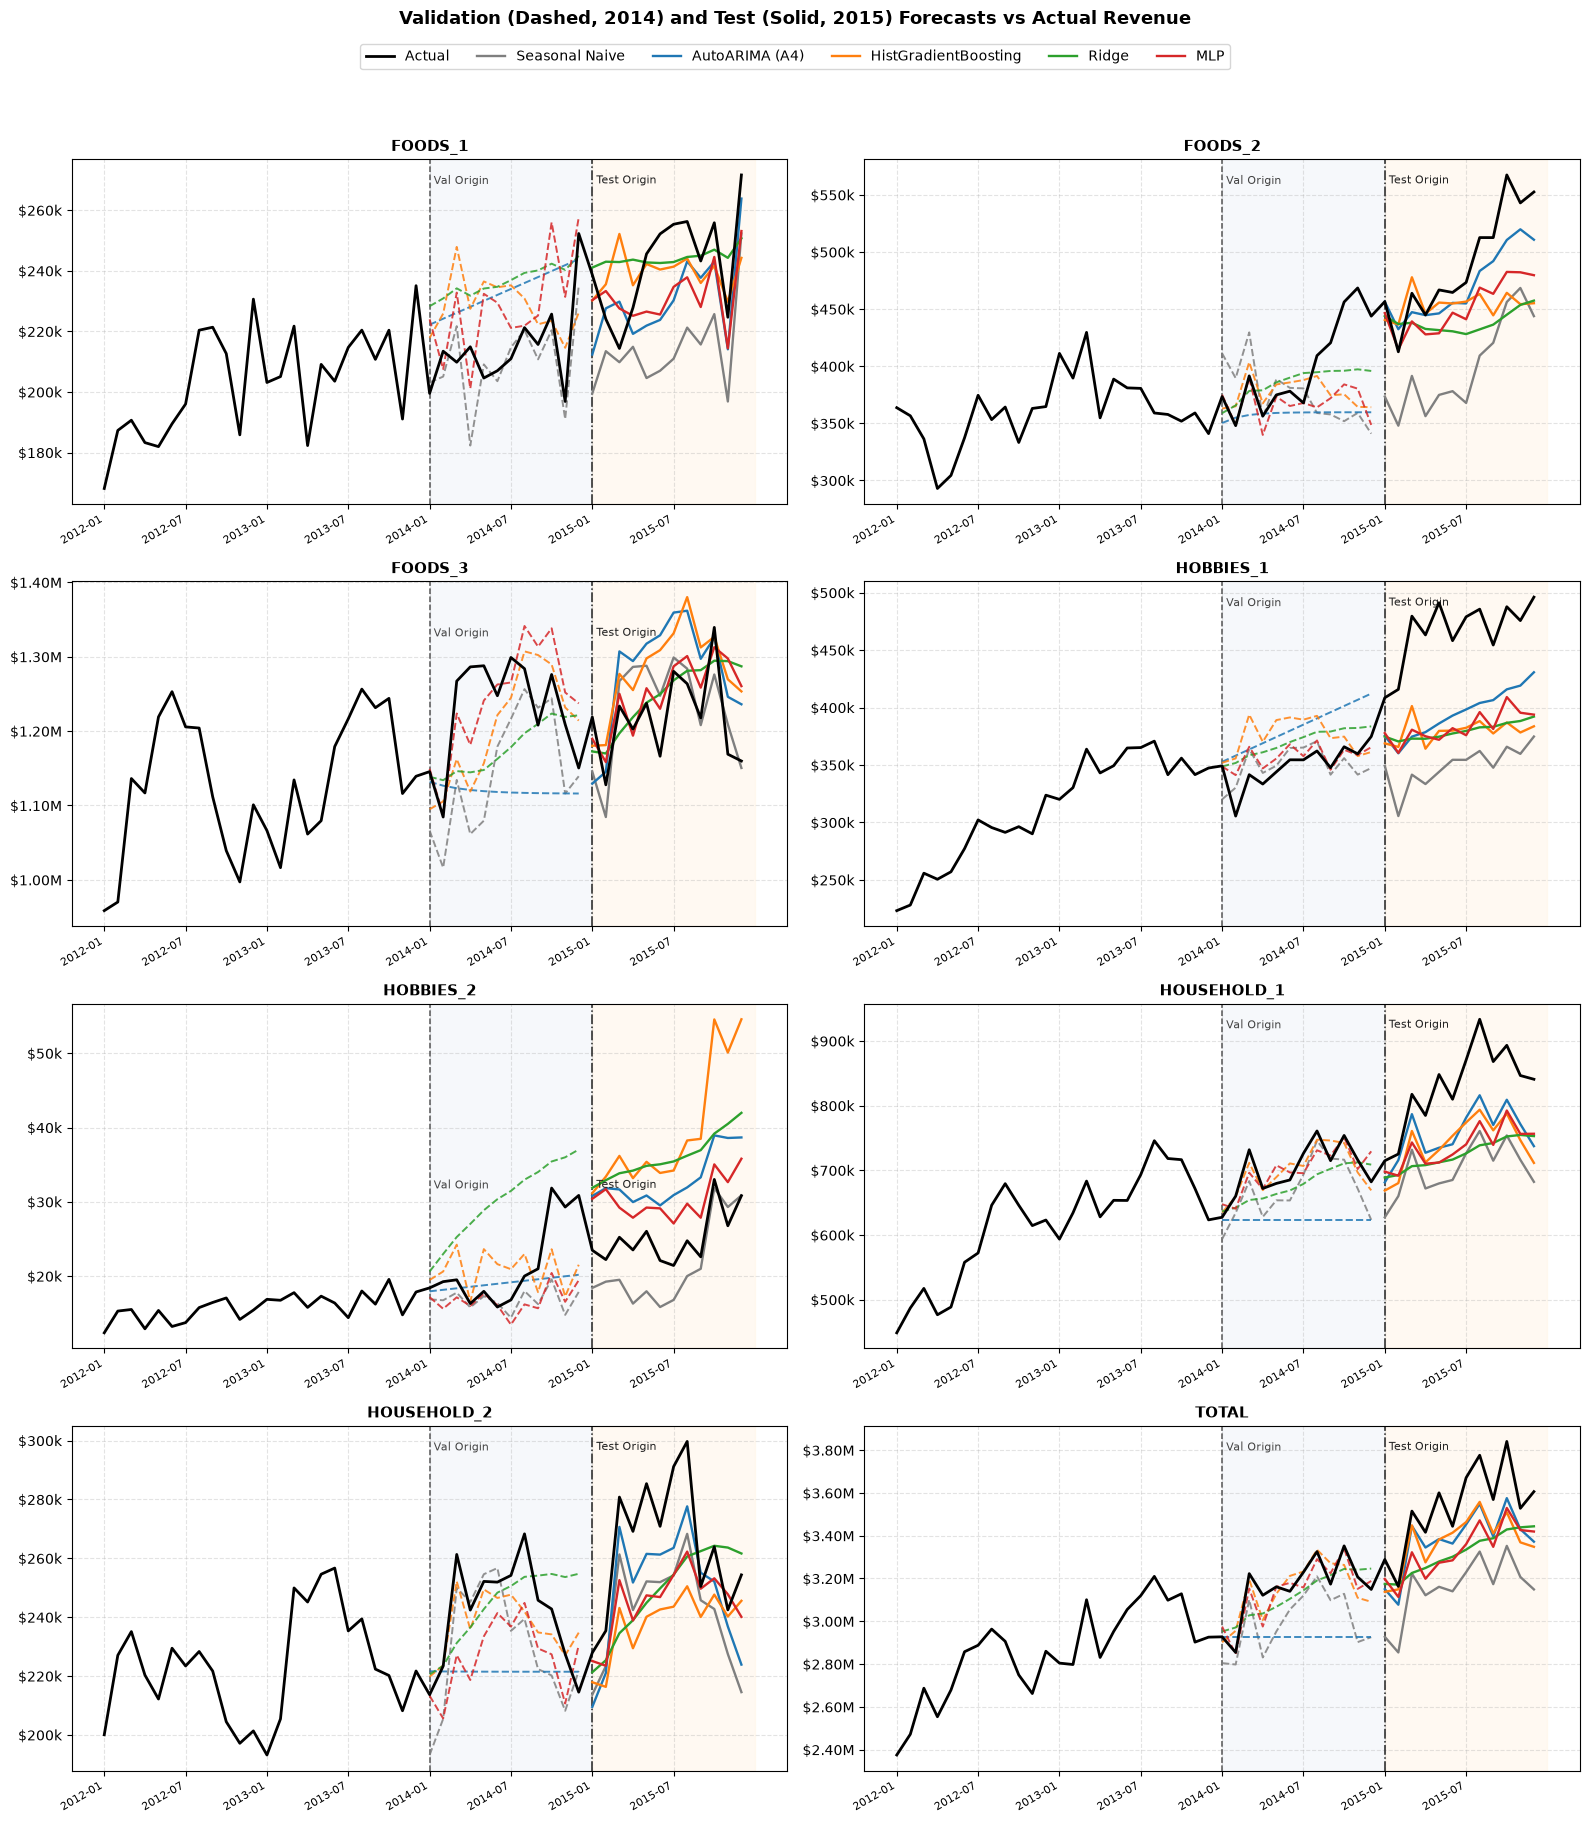

In [8]:
plot_keys = [
    ("Seasonal Naive", "Lag 12"),
    ("AutoARIMA (A4)", "Univariate"),
    ("HistGradientBoosting", "Lag + statistical"),
    ("Ridge", "Lag"),
    ("MLP", "Lag (12m)"),
]
colors = {
    "Seasonal Naive": "#7f7f7f",
    "AutoARIMA (A4)": "#1f77b4",
    "HistGradientBoosting": "#ff7f0e",
    "Ridge": "#2ca02c",
    "MLP": "#d62728",
}

months = df_top.index.tolist()
x_all = np.arange(48)
x_val = np.arange(24, 36)
x_test = np.arange(36, 48)
top_series = depts + ["TOTAL"]

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()

for idx, sname in enumerate(top_series):
    ax = axes[idx]
    y_actual = df_top[sname].values
    ax.plot(x_all, y_actual, color="black", linewidth=2.0, label="Actual", zorder=5)

    ax.axvline(x=24, color="#555555", linestyle="--", linewidth=1.1)
    ax.axvline(x=36, color="#222222", linestyle="-.", linewidth=1.1)
    ax.axvspan(24, 36, color="#eef3f8", alpha=0.5)
    ax.axvspan(36, 48, color="#fff5e6", alpha=0.5)

    y_max = y_actual.max()
    ax.text(24.3, y_max, "Val Origin", fontsize=8, va="top", color="#444444")
    ax.text(36.3, y_max, "Test Origin", fontsize=8, va="top", color="#222222")

    for mname, fs in plot_keys:
        c = colors[mname]
        ax.plot(x_val, val_top_preds[(mname, fs)][sname].values, color=c, linestyle="--", linewidth=1.4, alpha=0.85)
        ax.plot(x_test, test_top_preds[(mname, fs)][sname].values, color=c, linestyle="-", linewidth=1.7, label=mname)

    ax.set_title(sname, fontsize=11, fontweight="bold")
    ax.set_xticks(range(0, 48, 6))
    ax.set_xticklabels([months[i] for i in range(0, 48, 6)], rotation=30, ha="right", fontsize=8)
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda v, p: f"${v*1e-3:,.0f}k" if abs(v) < 1e6 else f"${v*1e-6:,.2f}M")
    )
    ax.grid(True, linestyle="--", alpha=0.35)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.995), ncol=6, fontsize=10)
fig.suptitle("Validation (Dashed, 2014) and Test (Solid, 2015) Forecasts vs Actual Revenue", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout(rect=[0, 0, 1, 0.965])
plt.show()

### Figure 2: Bottom-Level Scatter Plots (True vs Predicted, 840 Points, Test 2015)

Left: best Deep Learning model (`MLP`). Right: best Machine Learning model (`RandomForest` by Test Bottom MAE). Both share identical axes and include the 45 degree line.

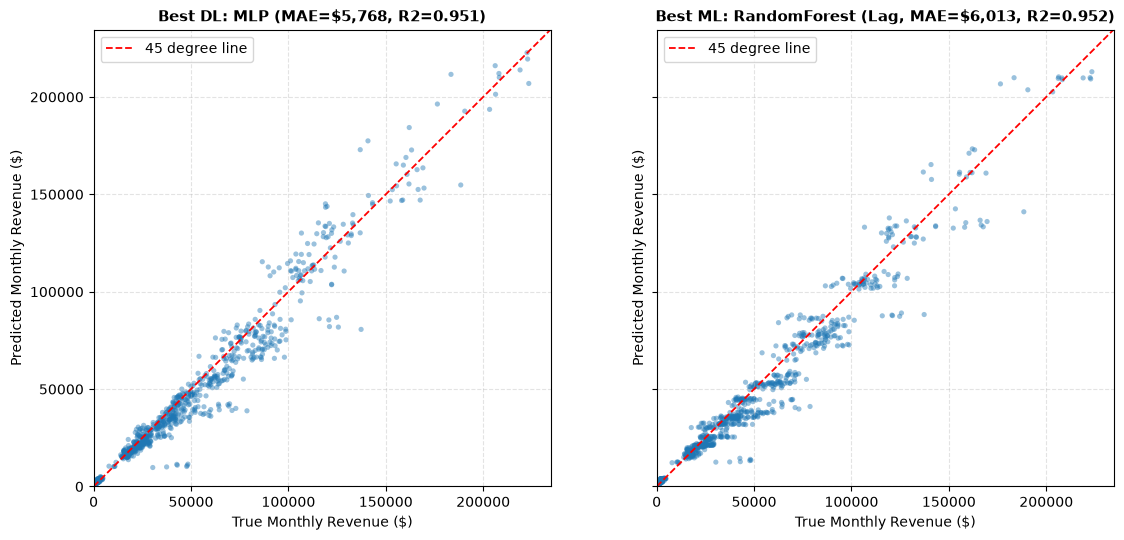

In [9]:
bot_sub = results_df[results_df["Level"] == "Department + Store"]
dl_names = {"MLP", "NHITS", "KAN"}
ml_names = {"Ridge", "HistGradientBoosting", "RandomForest"}

best_dl_row = bot_sub[bot_sub["Model"].isin(dl_names)].sort_values("MAE").iloc[0]
best_ml_row = bot_sub[bot_sub["Model"].isin(ml_names)].sort_values("MAE").iloc[0]

best_dl_key = (best_dl_row["Model"], best_dl_row["Feature set"])
best_ml_key = (best_ml_row["Model"], best_ml_row["Feature set"])

y_true_840 = test_true_bot.values.ravel()
y_dl_840 = test_bot_preds[best_dl_key].values.ravel()
y_ml_840 = test_bot_preds[best_ml_key].values.ravel()

lim_min = 0.0
lim_max = max(y_true_840.max(), y_dl_840.max(), y_ml_840.max()) * 1.05

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)

for ax, y_pred, title in [
    (axes[0], y_dl_840, f"Best DL: {best_dl_key[0]} (MAE=${best_dl_row['MAE']:,.0f}, R2={best_dl_row['R2']:.3f})"),
    (axes[1], y_ml_840, f"Best ML: {best_ml_key[0]} ({best_ml_key[1]}, MAE=${best_ml_row['MAE']:,.0f}, R2={best_ml_row['R2']:.3f})"),
]:
    ax.scatter(y_true_840, y_pred, s=14, alpha=0.45, color="#1f77b4", edgecolors="none")
    ax.plot([lim_min, lim_max], [lim_min, lim_max], color="red", linestyle="--", linewidth=1.3, label="45 degree line")
    ax.set_xlim(lim_min, lim_max)
    ax.set_ylim(lim_min, lim_max)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("True Monthly Revenue ($)")
    ax.set_ylabel("Predicted Monthly Revenue ($)")
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

## Step 8 - Argumentation

### 1. Which model is best at the bottom level, by MAE? Which is best at the top level, by wMAPE? Is it the same model?

- Bottom level (`Department + Store`, all 70 series): `MLP` is best by MAE ($5,768.09, MASE 0.942, R2 0.951), ahead of `KAN` ($5,904.18) and `RandomForest` ($6,012.90).
- Top level (`TOTAL`, by wMAPE): `AutoARIMA (A4)` is best overall at 4.42% wMAPE. Among the global bottom-up models, `HistGradientBoosting` (`Lag + statistical`) is best on `TOTAL` at 4.60% wMAPE, followed by `NHITS` at 5.26%.
- Department level: wins are split across models. `AutoARIMA (A4)` wins 3 departments (`FOODS_2`, `HOBBIES_1`, `HOUSEHOLD_1`), `KAN` wins 2 (`FOODS_1`, `HOUSEHOLD_2`), `RandomForest` wins 1 (`FOODS_3`), and `Seasonal Naive` wins 1 (`HOBBIES_2`).
- It is not the same model. A model with larger individual store-department errors can still win on `TOTAL` when positive and negative errors across the 70 series cancel out after summing.

### 2. Does deep learning beat the tabular models?

- At the bottom level: Yes. `MLP` ($5,768.09 MAE) and `KAN` ($5,904.18 MAE) beat all three tabular ML models (`RandomForest` $6,012.90, `Ridge` $6,108.67, `HistGradientBoosting` $6,316.51). Forecasting all 12 months directly with per-series scaling avoids the recursive error buildup of 1-step-ahead tabular models. Only `NHITS` ($6,387.09) is worse than the tabular models at the bottom level.
- At the top level (`TOTAL` wMAPE): Mixed. `HistGradientBoosting` (4.60%) beats all three deep learning models (`NHITS` 5.26%, `KAN` 5.55%, `MLP` 5.83%), while all three deep learning models beat `Ridge` (6.18%) and `RandomForest` (6.83%).

### 3. Do they beat the seasonal naive, and your best statistical model from Assignment 4?

- Against `Seasonal Naive` (Bottom MAE $7,405.49, TOTAL wMAPE 10.74%): Yes, by a wide margin. Every ML and DL model beats `Seasonal Naive` at the bottom level and on `TOTAL`. The only exception is the tiny, noisy `HOBBIES_2` department, where `Seasonal Naive` (16.57% wMAPE) beats all other models.
- Against `AutoARIMA (A4)` (best statistical model from Assignment 4, TOTAL wMAPE 4.42%): On `TOTAL`, `AutoARIMA` still beats every global ML and DL model, though `HistGradientBoosting` (4.60%) is close. Across the 7 departments, `AutoARIMA` wins 3 (`FOODS_2`, `HOBBIES_1`, `HOUSEHOLD_1`), while global ML/DL models beat `AutoARIMA` on `FOODS_1`, `FOODS_3`, `HOBBIES_2`, and `HOUSEHOLD_2`. Unlike the global models, `AutoARIMA` was fitted per department and has no store-level forecast.

### 4. Is 24 months enough to choose on? You picked on 2014 and reported on 2015.

- Not reliably. With 24 months of training data and 12-month lags, each series has only 12 training points for ML and only 1 training window (12 in, 12 out) for DL.
- At the bottom level, the validation winner (`MLP`, $4,369.37 MAE in 2014) did hold on Test ($5,768.09 MAE in 2015). However, the ML ranking flipped: `Ridge` beat `RandomForest` on Validation ($4,512.59 vs $4,704.21), but `RandomForest` beat `Ridge` on Test ($6,012.90 vs $6,108.67).
- At the top `TOTAL` level, validation failed completely: `MLP` won 2014 (1.52% wMAPE) and `AutoARIMA` finished last (7.66%, because 24 months is too short for `AutoARIMA` to fit 12-month seasonality). Once 36 months were available in 2015, `AutoARIMA` jumped from last to first (4.42%), while `MLP` fell to 5.83%.
- Two years of monthly data is too short for stable selection, especially when revenue growth speeds up in 2015 and models unlock seasonal behavior with a third year of history.